# 05 — Model Comparison and Uncertainty
Combine univariate and multivariate results, compare error metrics, assess prediction-interval coverage, and document uncertainty limitations. Run notebooks 03 and 04 first.

In [23]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve project root from any nested notebook directory.
HERE = Path.cwd().resolve()
REPO_ROOT = next((p for p in [HERE, *HERE.parents] if (p / "src" / "features.py").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook somewhere inside the project folder containing src/features.py.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from src.features import create_lagged_features

DATA_FILE = REPO_ROOT / "Data" / "lithium_consolidated_monthly.csv"
RESULTS_DIR = REPO_ROOT / "Results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42
df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
print("Project root:", REPO_ROOT)
print("Data:", DATA_FILE)

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, learning_curve

EXCLUDED = {
    TARGET, "Selected target source", "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "OLD - faulty cobalt settlement series (constant; excluded)",
    "China spot price open (CNY/t) - CSV", "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV", "China spot price volume (CSV)",
    "China spot price change (%) - CSV",
}
ALL_PREDICTORS = [c for c in df.select_dtypes(include=np.number).columns if c not in EXCLUDED]

def supervised_frame(horizon=1, n_lags=12, exog_cols=None):
    # Each row at origin t uses only observations through t-1.
    cols = [TARGET] + (list(exog_cols) if exog_cols else [])
    raw = df[cols].copy()
    lagged = create_lagged_features(raw, columns=cols, min_lag=1, max_lag=n_lags)
    y = df[TARGET].shift(-(horizon - 1)).rename("target")
    joined = lagged.join(y)
    # Retain valid labels even when one or more optional predictors are missing.
    joined = joined.dropna(subset=["target"])
    # Re-label rows by the month being forecast, not the feature-origin month.
    target_index = joined.index + pd.offsets.MonthBegin(horizon - 1)
    joined.index = target_index
    return joined.drop(columns="target"), joined["target"]

def chronological_split(X, y, test_fraction=0.20):
    cut = int(len(X) * (1-test_fraction))
    return X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]

def model_bank():
    return {
        "Linear Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
        "KNN": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
        "SVR": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR(C=10, epsilon=0.1)),
        "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=250, min_samples_leaf=2, random_state=RANDOM_STATE)),
        "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"), GradientBoostingRegressor(random_state=RANDOM_STATE)),
    }

def score(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": mean_squared_error(y, pred)**0.5,
            "R2": r2_score(y, pred)}

def calibration_residuals(X_train, y_train, model_name, calibration_fraction=0.20):
    """Out-of-sample residuals from a trailing calibration segment within training data."""
    cut = int(len(X_train) * (1-calibration_fraction))
    X_fit, X_cal = X_train.iloc[:cut], X_train.iloc[cut:]
    y_fit, y_cal = y_train.iloc[:cut], y_train.iloc[cut:]
    if len(X_fit) < 20 or len(X_cal) < 5:
        raise ValueError("Not enough training observations for residual calibration.")
    cal_model = model_bank()[model_name]
    cal_model.fit(X_fit, y_fit)
    return (y_cal - cal_model.predict(X_cal)).to_numpy()

def moving_block_sample(values, n, block=3, rng=None):
    rng = np.random.default_rng(RANDOM_STATE) if rng is None else rng
    values = np.asarray(values)
    if len(values) == 0:
        raise ValueError("Residual calibration set is empty.")
    out = []
    while len(out) < n:
        start = int(rng.integers(0, max(1, len(values)-block+1)))
        out.extend(values[start:start+block])
    return np.asarray(out[:n])

def prediction_interval(pred, residuals, n_boot=1500, block=3, seed=42):
    rng = np.random.default_rng(seed)
    sims = np.vstack([pred + moving_block_sample(residuals, len(pred), block, rng) for _ in range(n_boot)])
    return np.quantile(sims, 0.025, axis=0), np.quantile(sims, 0.975, axis=0)

def plot_forecast(y_test, pred, lower, upper, title, filename, zoom_n=36):
    fig, ax = plt.subplots(figsize=(13,5))
    ax.plot(y_test.index, y_test.values, label="Observed", linewidth=2)
    ax.plot(y_test.index, pred, label="Central prediction", linewidth=1.7)
    ax.plot(y_test.index, upper, color="tab:red", linewidth=1, label="Upper prediction")
    ax.plot(y_test.index, lower, color="tab:red", linewidth=1, label="Lower prediction")
    ax.fill_between(y_test.index, lower, upper, color="tab:red", alpha=.13, label="95% prediction interval")
    ax.set(title=title, xlabel="Target month", ylabel="Lithium carbonate price (CNY/tonne)")
    ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=180); plt.show()
    if len(y_test) > zoom_n:
        fig, ax = plt.subplots(figsize=(13,5))
        ax.plot(y_test.index[-zoom_n:], y_test.values[-zoom_n:], label="Observed", linewidth=2)
        ax.plot(y_test.index[-zoom_n:], pred[-zoom_n:], label="Central prediction")
        ax.fill_between(y_test.index[-zoom_n:], lower[-zoom_n:], upper[-zoom_n:], color="tab:red", alpha=.16, label="95% prediction interval")
        ax.set(title=title + " — zoomed view", xlabel="Target month", ylabel="CNY/tonne")
        ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
        fig.savefig(FIGURES_DIR / filename.replace(".png", "_zoomed.png"), dpi=180); plt.show()

def plot_learning_curve(model, X, y, title, filename):
    cv = TimeSeriesSplit(n_splits=4)
    sizes = np.linspace(.45, 1.0, 4)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X, y, cv=cv, train_sizes=sizes,
        scoring="neg_mean_squared_error", n_jobs=None
    )
    train_rmse = np.sqrt(-train_scores).mean(axis=1)
    val_rmse = np.sqrt(-val_scores).mean(axis=1)
    fig, ax = plt.subplots(figsize=(8,5))
    ax.plot(train_sizes, train_rmse, marker="o", label="Training RMSE")
    ax.plot(train_sizes, val_rmse, marker="o", label="Validation RMSE")
    ax.set(title=title, xlabel="Number of training observations", ylabel="RMSE")
    ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=180); plt.show()
    return pd.DataFrame({"Training observations":train_sizes,"Training RMSE":train_rmse,"Validation RMSE":val_rmse})

Project root: /home/schmidlucy/Lucy-Schmid.github.io
Data: /home/schmidlucy/Lucy-Schmid.github.io/Data/lithium_consolidated_monthly.csv


## Load results

In [24]:
uni=pd.read_csv(TABLES_DIR/"univariate_model_comparison.csv")
multi=pd.read_csv(TABLES_DIR/"multivariate_model_comparison.csv")
uni["Approach"]="Univariate"; multi["Approach"]=multi["Feature set"]
comparison=pd.concat([uni[["Approach","Horizon","Model","MAE","RMSE","R2"]],
                      multi[["Approach","Horizon","Model","MAE","RMSE","R2"]]],ignore_index=True)
display(comparison.sort_values(["Horizon","RMSE"]))
comparison.to_csv(TABLES_DIR/"all_model_comparisons.csv",index=False)

,Approach,Horizon,Model,MAE,RMSE,R2
0,Univariate,1,Random Forest,1.938414e+04,2.804715e+04,7.628383e-01
1,Univariate,1,Gradient Boosting,2.573835e+04,3.979501e+04,5.225540e-01
2,Univariate,1,Linear Regression,2.736148e+04,4.336608e+04,4.330205e-01
3,Univariate,1,Ridge,3.710138e+04,5.310252e+04,1.498464e-01
24,With Japan index,1,Gradient Boosting,5.929519e+04,6.672999e+04,-3.424843e-01
...,...,...,...,...,...,...
67,Without Japan index,12,KNN,2.813375e+05,3.008025e+05,-3.749113e+01
68,With Japan index,12,Ridge,4.548477e+05,4.814836e+05,-9.761901e+01
69,Without Japan index,12,Ridge,4.741750e+05,4.965905e+05,-1.039046e+02
70,Without Japan index,12,Linear Regression,9.802049e+05,1.020024e+06,-4.416072e+02


## Best model by approach and horizon

In [25]:
best=comparison.loc[comparison.groupby(["Approach","Horizon"])["RMSE"].idxmin()].sort_values(["Horizon","RMSE"])
display(best); best.to_csv(TABLES_DIR/"best_model_by_approach_and_horizon.csv",index=False)

,Approach,Horizon,Model,MAE,RMSE,R2
0,Univariate,1,Random Forest,19384.135720,28047.153105,0.762838
24,With Japan index,1,Gradient Boosting,59295.190201,66729.993107,-0.342484
25,Without Japan index,1,Gradient Boosting,67775.154280,74948.082200,-0.693511
6,Univariate,3,Gradient Boosting,51090.795953,82100.382036,-1.032158
36,With Japan index,3,SVR,75050.750625,94601.368291,-1.698124
37,Without Japan index,3,SVR,75051.142286,94601.594769,-1.698137
12,Univariate,6,Gradient Boosting,59704.509177,77115.837858,-0.918980
48,With Japan index,6,SVR,71923.156954,90949.538312,-1.669220
49,Without Japan index,6,SVR,71924.018640,90950.173066,-1.669257
18,Univariate,12,KNN,47150.400000,63657.587383,-0.723844


## RMSE heatmap

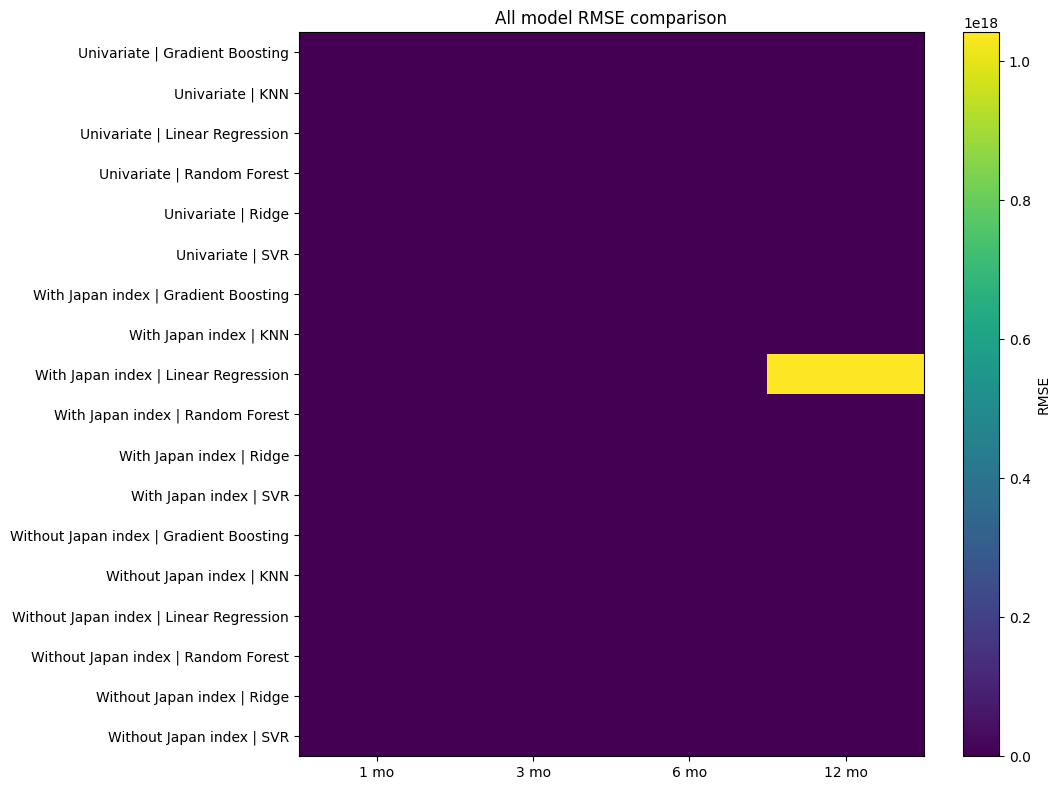

In [26]:
pivot=comparison.pivot_table(index=["Approach","Model"],columns="Horizon",values="RMSE")
fig,ax=plt.subplots(figsize=(11,8)); im=ax.imshow(pivot.values,aspect="auto")
ax.set_yticks(range(len(pivot.index)),[f"{a} | {m}" for a,m in pivot.index])
ax.set_xticks(range(len(pivot.columns)),[f"{h} mo" for h in pivot.columns])
fig.colorbar(im,ax=ax,label="RMSE"); ax.set_title("All model RMSE comparison")
plt.tight_layout(); fig.savefig(FIGURES_DIR/"15_all_model_rmse_heatmap.png",dpi=180); plt.show()

## Best RMSE by approach and horizon

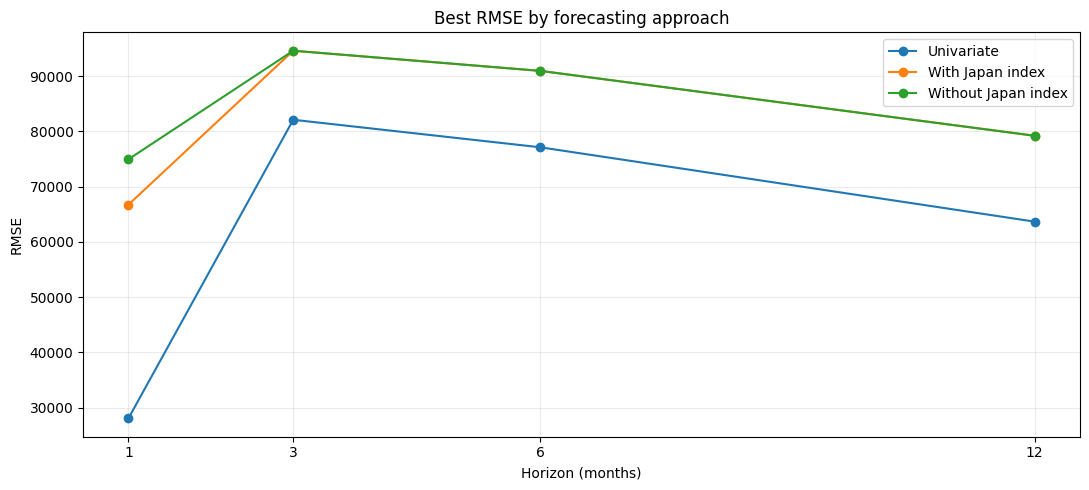

In [27]:
fig,ax=plt.subplots(figsize=(11,5))
for name,g in best.groupby("Approach"): ax.plot(g.Horizon,g.RMSE,marker="o",label=name)
ax.set(title="Best RMSE by forecasting approach",xlabel="Horizon (months)",ylabel="RMSE")
ax.set_xticks([1,3,6,12]); ax.grid(alpha=.25); ax.legend()
plt.tight_layout(); fig.savefig(FIGURES_DIR/"16_best_rmse_by_approach.png",dpi=180); plt.show()

## MAE and R-squared comparisons

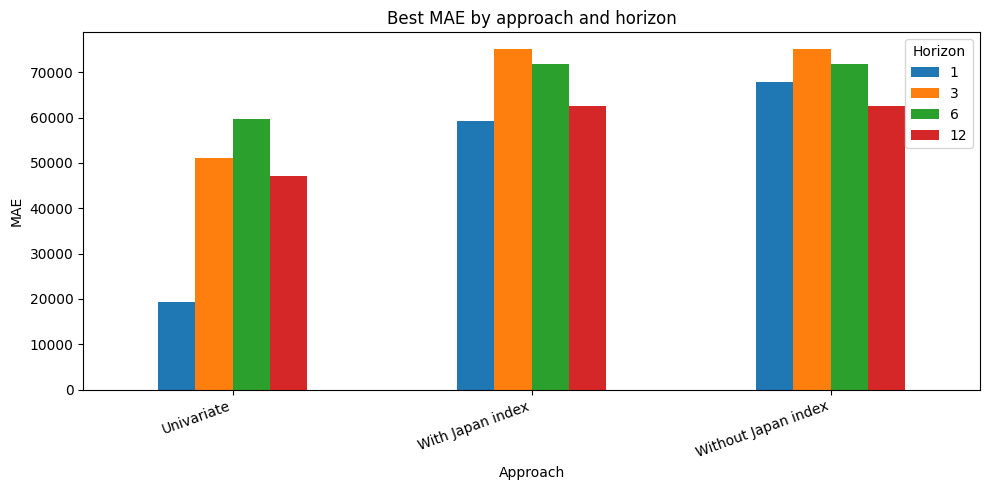

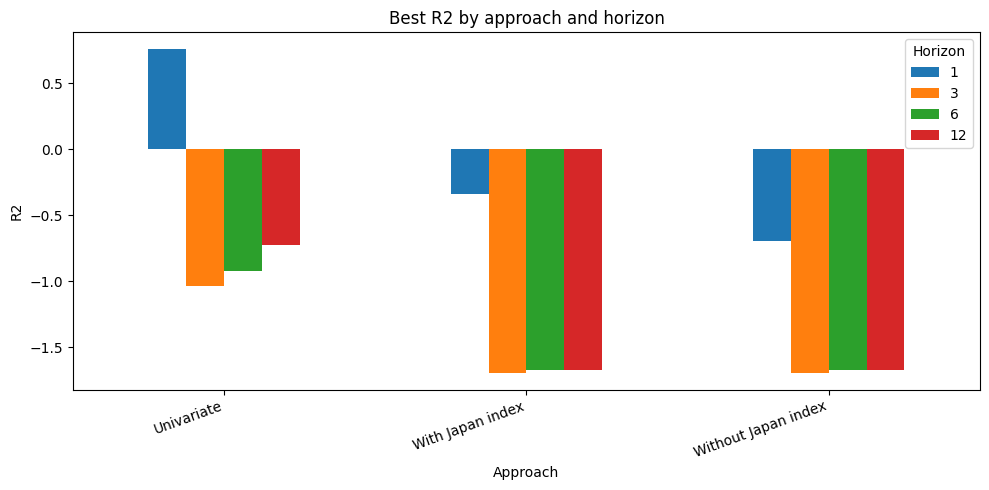

In [28]:
for metric in ["MAE","R2"]:
    p=best.pivot(index="Approach",columns="Horizon",values=metric)
    fig,ax=plt.subplots(figsize=(10,5)); p.plot(kind="bar",ax=ax)
    ax.set(title=f"Best {metric} by approach and horizon",ylabel=metric)
    plt.xticks(rotation=20,ha="right"); plt.tight_layout()
    fig.savefig(FIGURES_DIR/f"17_best_{metric.lower()}_comparison.png",dpi=180); plt.show()

## Interval coverage comparison

,Approach,Empirical coverage,Mean interval width
0,Univariate,0.452381,398955.155608
1,Best multivariate,0.071429,394436.362677


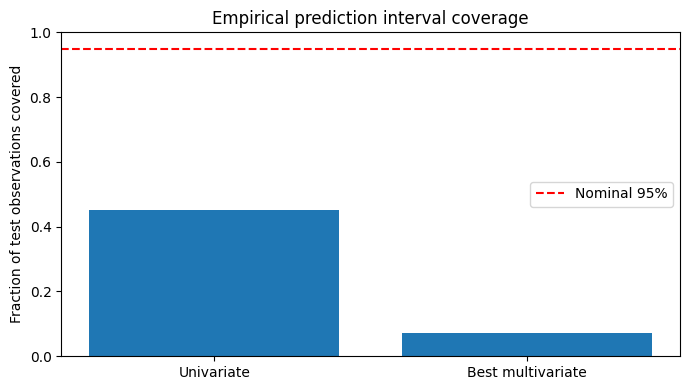

In [29]:
# Prediction intervals are produced in notebooks 03 and 04 using residuals
# calibrated on a trailing slice of training data, never on the final test set.
coverage_rows=[]
for fn,label in [("univariate_1month_predictions_and_intervals.csv","Univariate"),
                 ("multivariate_1month_predictions_and_intervals.csv","Best multivariate")]:
    d=pd.read_csv(TABLES_DIR/fn)
    covered=(d["actual"]>=d["lower_95"])&(d["actual"]<=d["upper_95"])
    coverage_rows.append({"Approach":label,"Empirical coverage":covered.mean(),
                          "Mean interval width":(d["upper_95"]-d["lower_95"]).mean()})
interval_summary=pd.DataFrame(coverage_rows)
display(interval_summary); interval_summary.to_csv(TABLES_DIR/"prediction_interval_coverage.csv",index=False)
fig,ax=plt.subplots(figsize=(7,4)); ax.bar(interval_summary.Approach,interval_summary["Empirical coverage"])
ax.axhline(.95,color="red",linestyle="--",label="Nominal 95%")
ax.set(ylim=(0,1),title="Empirical prediction interval coverage",ylabel="Fraction of test observations covered")
ax.legend(); plt.tight_layout(); fig.savefig(FIGURES_DIR/"18_prediction_interval_coverage.png",dpi=180); plt.show()

## Interpretation
- Lower MAE and RMSE indicate smaller forecast errors.
- R² is useful but can be negative on a difficult time-series test set.
- Prediction interval coverage should be considered alongside interval width; wide intervals can achieve high coverage but be less informative.
- The intervals are approximate block-bootstrap prediction intervals based on out-of-sample calibration residuals from a trailing portion of the training set. They are not guaranteed to achieve exactly 95% coverage.
- Do not choose a model based on training error alone. Prioritize chronological holdout and rolling-origin validation.

## Low / Medium / High price-regime classification

This section classifies the lithium carbonate price into **Low**, **Medium**, and **High** regimes using thresholds calculated from the training period only. The final test period is classified using those fixed thresholds, avoiding leakage from future prices.

The models predict the next month's price regime from lagged price observations. This is a separate classification task from the regression models above.

In [30]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

# One-month-ahead labels: features through month t-1 predict the regime in month t.
X_cls = create_lagged_features(df[[TARGET]].dropna(), columns=[TARGET], min_lag=1, max_lag=12)
y_price = df[TARGET].dropna()
cls_data = X_cls.join(y_price.rename("price_to_classify")).dropna(subset=["price_to_classify"])
X_cls = cls_data.drop(columns="price_to_classify")
price = cls_data["price_to_classify"]

cut = int(len(cls_data) * 0.80)
X_train_cls, X_test_cls = X_cls.iloc[:cut], X_cls.iloc[cut:]
price_train, price_test = price.iloc[:cut], price.iloc[cut:]

# Tercile cutoffs are learned only from training-period prices.
low_cut, high_cut = price_train.quantile([1/3, 2/3]).tolist()
print(f"Training-set low/medium cutoff: {low_cut:,.0f} CNY/tonne")
print(f"Training-set medium/high cutoff: {high_cut:,.0f} CNY/tonne")

def price_regime(values):
    return pd.cut(values, bins=[-np.inf, low_cut, high_cut, np.inf],
                  labels=["Low", "Medium", "High"], include_lowest=True)

y_train_cls = price_regime(price_train)
y_test_cls = price_regime(price_test)
print("\\nTraining regime counts:")
display(y_train_cls.value_counts().reindex(["Low","Medium","High"]))
print("\\nTest regime counts:")
display(y_test_cls.value_counts().reindex(["Low","Medium","High"]))

Training-set low/medium cutoff: 37,167 CNY/tonne
Training-set medium/high cutoff: 82,333 CNY/tonne
\nTraining regime counts:


price_to_classify
Low       56
Medium    55
High      56
Name: count, dtype: int64

\nTest regime counts:


price_to_classify
Low        0
Medium    15
High      27
Name: count, dtype: int64

### Fit Logistic Regression and Random Forest classifiers

\nLogistic Regression classification report
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         0
      Medium       0.58      1.00      0.73        15
        High       1.00      0.59      0.74        27

   micro avg       0.74      0.74      0.74        42
   macro avg       0.53      0.53      0.49        42
weighted avg       0.85      0.74      0.74        42



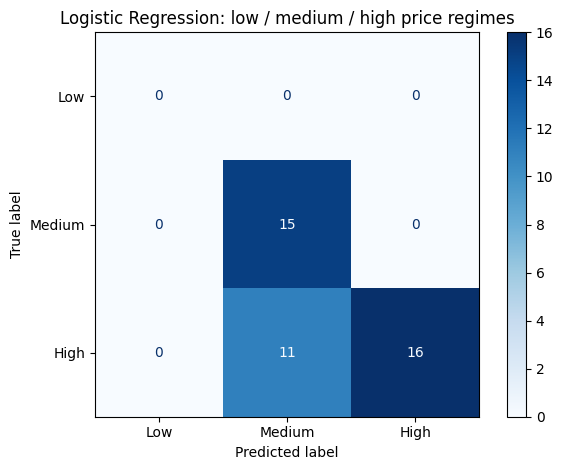

\nRandom Forest classification report
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         0
      Medium       0.82      0.93      0.88        15
        High       0.96      0.89      0.92        27

   micro avg       0.90      0.90      0.90        42
   macro avg       0.59      0.61      0.60        42
weighted avg       0.91      0.90      0.91        42



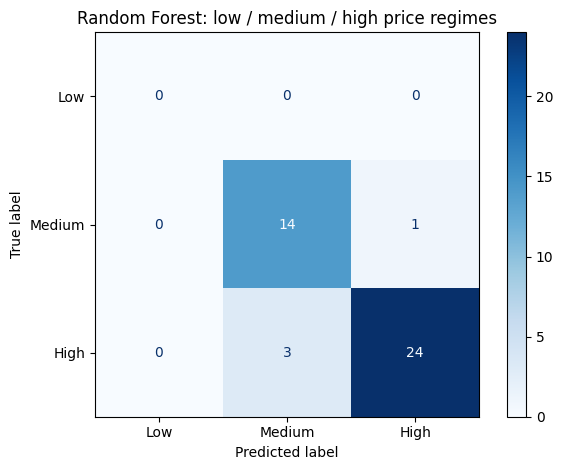

,Model,Accuracy,Macro F1
1,Random Forest,0.904762,0.899038
0,Logistic Regression,0.738095,0.737947


In [31]:
classifiers = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                               class_weight="balanced_subsample", random_state=RANDOM_STATE)
    )
}

class_rows = []
class_predictions = {}
for name, clf in classifiers.items():
    clf.fit(X_train_cls, y_train_cls)
    pred_cls = clf.predict(X_test_cls)
    class_predictions[name] = pred_cls
    class_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_cls, pred_cls),
        "Macro F1": f1_score(y_test_cls, pred_cls, average="macro", zero_division=0)
    })
    print(f"\\n{name} classification report")
    print(classification_report(y_test_cls, pred_cls, labels=["Low","Medium","High"], zero_division=0))
    cm = confusion_matrix(y_test_cls, pred_cls, labels=["Low","Medium","High"])
    disp = ConfusionMatrixDisplay(cm, display_labels=["Low","Medium","High"])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{name}: low / medium / high price regimes")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"21_{name.lower().replace(' ','_')}_regime_confusion_matrix.png", dpi=180)
    plt.show()

class_results = pd.DataFrame(class_rows).sort_values("Macro F1", ascending=False)
display(class_results)
class_results.to_csv(TABLES_DIR / "low_medium_high_classification_metrics.csv", index=False)

### Compare predicted and actual price regimes over time

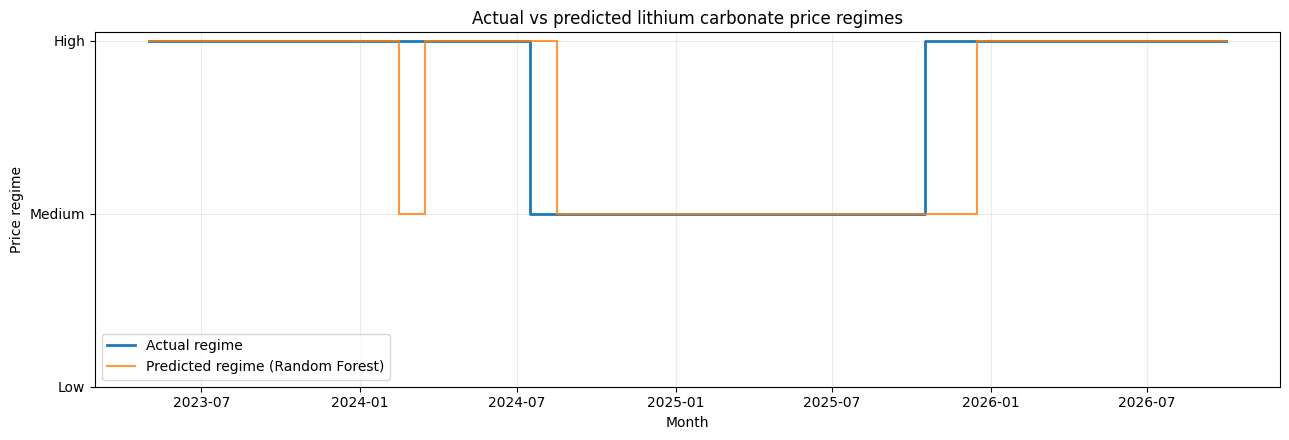

,Actual price,Actual regime,Predicted regime
Month,,,
2023-05-01,228125.0,High,High
2023-06-01,295600.0,High,High
2023-07-01,282500.0,High,High
2023-08-01,221400.0,High,High
2023-09-01,170500.0,High,High
2023-10-01,159125.0,High,High
2023-11-01,138200.0,High,High
2023-12-01,95125.0,High,High
2024-01-01,88275.0,High,High


In [32]:
best_classifier_name = class_results.iloc[0]["Model"]
best_classifier = classifiers[best_classifier_name]
best_cls_pred = class_predictions[best_classifier_name]

regime_order = ["Low", "Medium", "High"]
regime_codes = {"Low": 0, "Medium": 1, "High": 2}
actual_codes = pd.Series(y_test_cls.astype(str), index=y_test_cls.index).map(regime_codes)
pred_codes = pd.Series(best_cls_pred.astype(str), index=y_test_cls.index).map(regime_codes)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.step(y_test_cls.index, actual_codes, where="mid", label="Actual regime", linewidth=2)
ax.step(y_test_cls.index, pred_codes, where="mid", label=f"Predicted regime ({best_classifier_name})", alpha=.8)
ax.set_yticks([0,1,2], regime_order)
ax.set(title="Actual vs predicted lithium carbonate price regimes",
       xlabel="Month", ylabel="Price regime")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
fig.savefig(FIGURES_DIR / "22_actual_vs_predicted_price_regimes.png", dpi=180)
plt.show()

regime_output = pd.DataFrame({
    "Actual price": price_test,
    "Actual regime": y_test_cls.astype(str),
    "Predicted regime": pd.Series(best_cls_pred.astype(str), index=y_test_cls.index)
})
display(regime_output.head(15))
regime_output.to_csv(TABLES_DIR / "low_medium_high_regime_predictions.csv")

### Interpretation and limitations

- The cutoffs are the 33rd and 67th percentiles of the training-period target prices, so the three labels represent relative price regimes rather than fixed industry price bands.
- The cutoffs remain fixed when labeling the test period; they are not recalculated using test prices.
- Accuracy alone can be misleading if one regime dominates. Macro F1 gives each class equal weight, and the confusion matrices show which regimes are confused.
- This is a one-month-ahead classification task. The classifier should be compared with a simple persistence baseline (assuming next month's regime is the same as the latest observed regime) before claiming predictive value.
- Regime labels depend on the historical training window. They should not be interpreted as universal definitions of cheap, fair, or expensive lithium.

In [33]:
# Persistence baseline: predict that next month's regime matches the latest known regime.
latest_train_regime = y_train_cls.iloc[-1]
persistence_pred = pd.Series([latest_train_regime] * len(y_test_cls), index=y_test_cls.index)
persistence_metrics = {
    "Model": "Persistence baseline",
    "Accuracy": accuracy_score(y_test_cls, persistence_pred),
    "Macro F1": f1_score(y_test_cls, persistence_pred, average="macro", zero_division=0)
}
baseline_comparison = pd.concat([class_results, pd.DataFrame([persistence_metrics])], ignore_index=True)
display(baseline_comparison.sort_values("Macro F1", ascending=False))
baseline_comparison.to_csv(TABLES_DIR / "low_medium_high_classification_with_baseline.csv", index=False)

,Model,Accuracy,Macro F1
0,Random Forest,0.904762,0.899038
1,Logistic Regression,0.738095,0.737947
2,Persistence baseline,0.642857,0.391304
